# 09. Đánh Giá Tổng Hợp & So Sánh Toàn Diện Các Mô Hình (`/notebook/model`)
Notebook nạp trực tiếp toàn bộ các model artifacts trong `/notebook/model/`, đánh giá trên tập kiểm tra độc lập (20% test set) và vẽ đường cong ROC & Calibration (Reliability Diagram).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

from src.config import settings
from src.models.datasets import DATASETS, load_dataframe, mask_augment
from src.models.deep_mlp import MLPRisk
from src.models.tabular_ml import GradientBoostingRisk
from src.storage.db import engine

MODEL_DIR = settings.model_dir
spec = DATASETS["nhanes"]
df = load_dataframe(spec, engine)
X, y = df[spec.features].astype(float), df[spec.label].astype(int)
idx_tv, idx_te = train_test_split(df.index, test_size=0.20, random_state=42, stratify=y)
X_te, y_te = X.loc[idx_te], y.loc[idx_te].to_numpy()
X_te_masked = mask_augment(X_te, y.loc[idx_te], spec, p=0.4, seed=99)[0].iloc[len(X_te):]
asian_mask = (df.loc[idx_te, "asian"] == 1).to_numpy()

models = [
    ("Logistic Regression", "logistic_regression.joblib", lambda m, d: m.predict_proba(d)[:, 1], joblib.load(MODEL_DIR / "logistic_regression.joblib")),
    ("Random Forest", "random_forest.joblib", lambda m, d: m.predict_proba(d)[:, 1], joblib.load(MODEL_DIR / "random_forest.joblib")),
    ("Extra Trees", "extra_trees.joblib", lambda m, d: m.predict_proba(d)[:, 1], joblib.load(MODEL_DIR / "extra_trees.joblib")),
    ("HistGBDT (PredictionAgent ML)", "nhanes_gbdt.joblib", lambda m, d: m.predict_proba(d), GradientBoostingRisk.load(spec)),
    ("PyTorch MLP (PredictionAgent DL)", "nhanes_mlp.pt", lambda m, d: m.predict_proba(d), MLPRisk.load(spec)),
]

rows = []
preds = {}
for name, art, fn, mdl in models:
    p = fn(mdl, X_te)
    pm = fn(mdl, X_te_masked)
    preds[name] = p
    rows.append({
        "Mô hình": name,
        "Artifact (/notebook/model)": art,
        "ROC-AUC": round(float(roc_auc_score(y_te, p)), 4),
        "PR-AUC": round(float(average_precision_score(y_te, p)), 4),
        "Brier Score": round(float(brier_score_loss(y_te, p)), 4),
        "Masked AUC (khuyết 40%)": round(float(roc_auc_score(y_te, pm)), 4),
        "Asian Subgroup AUC": round(float(roc_auc_score(y_te[asian_mask], p[asian_mask])), 4),
    })

p_ens = 0.5 * preds["HistGBDT (PredictionAgent ML)"] + 0.5 * preds["PyTorch MLP (PredictionAgent DL)"]
preds["Ensemble (GBDT + MLP)"] = p_ens
rows.append({
    "Mô hình": "Ensemble (GBDT + MLP)",
    "Artifact (/notebook/model)": "nhanes_gbdt.joblib + nhanes_mlp.pt",
    "ROC-AUC": round(float(roc_auc_score(y_te, p_ens)), 4),
    "PR-AUC": round(float(average_precision_score(y_te, p_ens)), 4),
    "Brier Score": round(float(brier_score_loss(y_te, p_ens)), 4),
    "Masked AUC (khuyết 40%)": round(float(roc_auc_score(y_te, 0.5 * models[3][2](models[3][3], X_te_masked) + 0.5 * models[4][2](models[4][3], X_te_masked))), 4),
    "Asian Subgroup AUC": round(float(roc_auc_score(y_te[asian_mask], p_ens[asian_mask])), 4),
})

lb_df = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
lb_df.to_csv(MODEL_DIR / "evaluation_leaderboard.csv", index=False)
lb_df

Mô hình,Artifact (/notebook/model),ROC-AUC,PR-AUC,Brier Score,Masked AUC (khuyết 40%),Asian Subgroup AUC
Ensemble (GBDT + MLP),nhanes_gbdt.joblib + nhanes_mlp.pt,0.8252,0.5347,0.1217,0.8037,0.8428
PyTorch MLP (PredictionAgent DL),nhanes_mlp.pt,0.8250,0.5245,0.1228,0.8039,0.8438
Random Forest,random_forest.joblib,0.8185,0.5116,0.1243,0.7905,0.8356
HistGBDT (PredictionAgent ML),nhanes_gbdt.joblib,0.8167,0.5241,0.1241,0.7937,0.8332
Extra Trees,extra_trees.joblib,0.8104,0.4944,0.1271,0.7772,0.8281
Logistic Regression,logistic_regression.joblib,0.8099,0.4868,0.1280,0.7798,0.8406


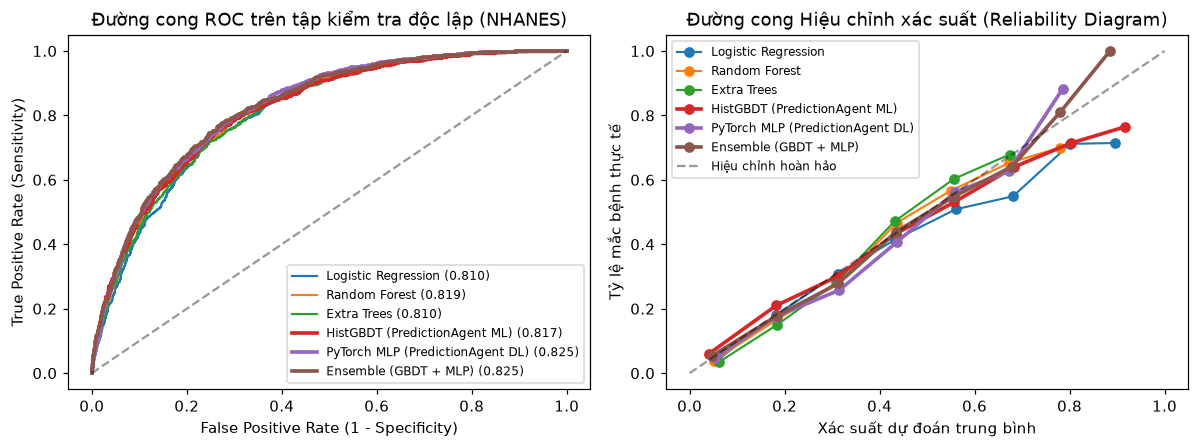

In [2]:
# Vẽ đường cong ROC và đường cong Hiệu chỉnh xác suất (Calibration Curve) của tất cả mô hình
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, p in preds.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    auc_val = roc_auc_score(y_te, p)
    lw = 2.4 if "Ensemble" in name or "PredictionAgent" in name else 1.4
    axes[0].plot(fpr, tpr, linewidth=lw, label=f"{name} ({auc_val:.3f})")
    prob_true, prob_pred = calibration_curve(y_te, p, n_bins=8)
    axes[1].plot(prob_pred, prob_true, marker="o", linewidth=lw, label=name)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("Đường cong ROC trên tập kiểm tra độc lập (NHANES)")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Sensitivity)")
axes[0].legend(fontsize=8)

axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4, label="Hiệu chỉnh hoàn hảo")
axes[1].set_title("Đường cong Hiệu chỉnh xác suất (Reliability Diagram)")
axes[1].set_xlabel("Xác suất dự đoán trung bình")
axes[1].set_ylabel("Tỷ lệ mắc bệnh thực tế")
axes[1].legend(fontsize=8)
plt.tight_layout()

In [3]:
# Kiểm kê toàn bộ danh sách file artifacts hiện có trong /notebook/model
pd.DataFrame([
    {"File Artifact": p.name, "Kích thước (KB)": round(p.stat().st_size / 1024, 1)}
    for p in sorted(MODEL_DIR.iterdir()) if p.is_file()
])

File Artifact,Kích thước (KB)
brfss_gbdt.joblib,1302.8
brfss_mlp.pt,63.8
cnn_retinopathy_resnet18.pt,43744.6
evaluation_leaderboard.csv,0.6
extra_trees.joblib,5387.0
logistic_regression.joblib,2.5
nhanes_gbdt.joblib,1423.4
nhanes_mlp.pt,65.8
random_forest.joblib,6183.9
rl_qtable.npz,1.0
